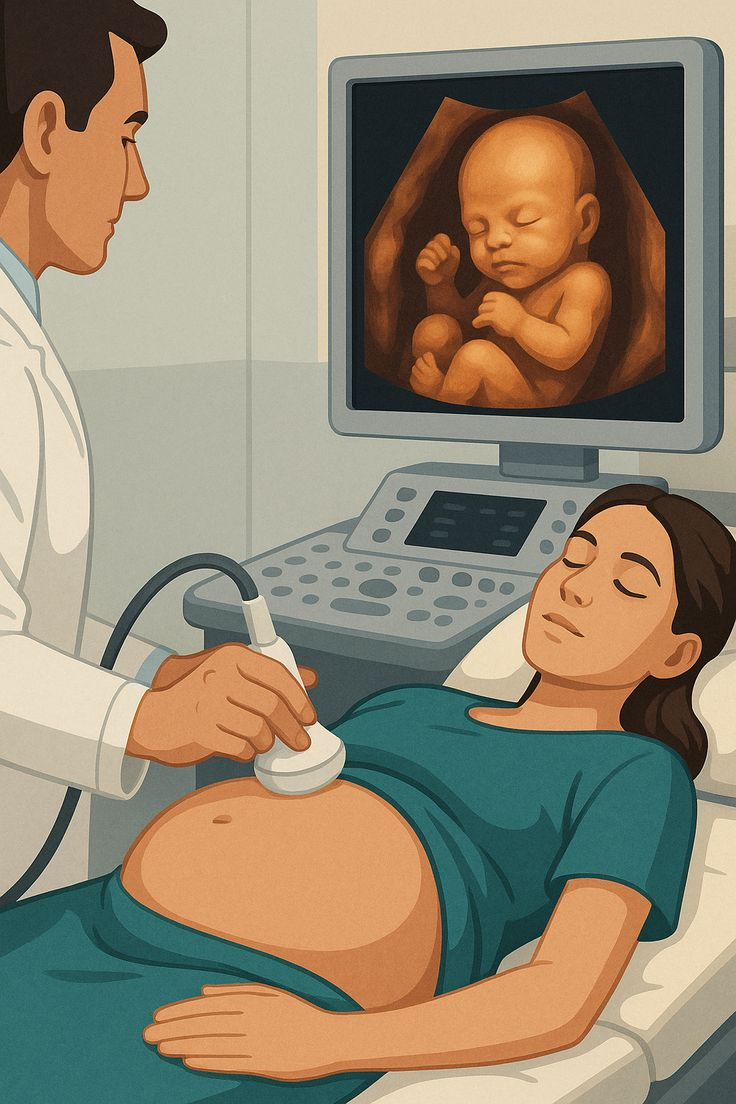


## **Maternal Health Risk Prediction Project**:***Who's More Likely to Face Pregnancy Complications?***

This notebook contains an end-to-end process of building and deploying a maternal health risk prediction machine learning model. The model predicts a pregnant woman's maternal health risk level based on certain clinical measurements. It also incorporates a Generative AI layer that explains each prediction in clear, human-friendly language.


### ***Problem Statement***

Maternal health remains a major public health concern, particularly in developing countries, like, Nigeria, where delayed identification of high-risk pregnancies can lead to serious complications for both the mother and baby. Early risk assessment allows healthcare professionals to provide closer monitoring and timely intervention when needed.

This project involves building a multiclass classification model that predicts whether a pregnant woman falls into a Low Risk, Mid Risk, or High Risk category using routine clinical measurements. To make the predictions more understandable, a Generative AI layer that explains each prediction in plain, easy-to-understand language would be integrated.

## ***About the Dataset***

The dataset used in this project contains maternal health records collected from pregnant women. It includes routine clinical measurements that are commonly assessed during antenatal visits and are used to predict a patient's maternal health risk level.

The dataset consists of 1,014 observations and 7 variables, where 6 variables serve as predictor features and 1 variable is the target variable.

### **Feature Description**

| Feature | Description |
|---------|-------------|
| **Age** | Age of the pregnant woman (in years) |
| **SystolicBP** | Systolic Blood Pressure (mmHg) |
| **DiastolicBP** | Diastolic Blood Pressure (mmHg) |
| **BS** | Blood Sugar level (mmol/L) |
| **BodyTemp** | Body Temperature (°F) |
| **HeartRate** | Heart Rate (beats per minute) |
| **RiskLevel** | Maternal health risk category (**Low Risk**, **Mid Risk**, or **High Risk**) |

In [ ]:
# Connecting notebook to google drive to be able to load datatset

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# importing necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Maternal Health Risk Data Set.csv")
df.head()  #displays the first 5 rows.

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [ ]:
# number of enteries

rows, cols = df.shape
print(f"The data has {rows} rows and {cols} columns.")


The data has 1014 rows and 7 columns.


In [ ]:
# getting more information about the data; datatypes and the likes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   object 
dtypes: float64(2), int64(4), object(1)
memory usage: 55.6+ KB


### ***Data Type Observations***

- A quick inspection of the dataset shows that all features are stored in their appropriate data types.
- The `RiskLevel` column is the only categorical variable in the dataset. Since it is the target variable, it will be encoded at the appropriate stage during data preprocessing before training the machine learning models.

In [ ]:
#check for null values
null_values = df.isna().sum()
print(f"The data has {null_values} number of null values")

The data has Age            0
SystolicBP     0
DiastolicBP    0
BS             0
BodyTemp       0
HeartRate      0
RiskLevel      0
dtype: int64 number of null values


The dataset has no null values.

In [ ]:
# check for duplicates

duplicate_values = df.duplicated().sum()
print(f"The data has {duplicate_values} number of duplicate values")

The data has 562 number of duplicate values


### ***Duplicate Value Observations***

- The dataset contains **562 duplicate rows**.
- However, these duplicates were **not removed** because the dataset does not contain a unique patient identifier. It is therefore possible for multiple pregnant women to share identical clinical measurements while representing different observations.
- To avoid unintentionally discarding valid records, all rows were retained for model development.

In [ ]:
# Let's get a description of our data

df.describe()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
count,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000
mean,29.871795,113.198225,76.460552,8.725986,98.665089,74.301775
std,13.474386,18.403913,13.885796,3.293532,1.371384,8.088702
min,10.000000,70.000000,49.000000,6.000000,98.000000,7.000000
25%,19.000000,100.000000,65.000000,6.900000,98.000000,70.000000
50%,26.000000,120.000000,80.000000,7.500000,98.000000,76.000000
75%,39.000000,120.000000,90.000000,8.000000,98.000000,80.000000
max,70.000000,160.000000,100.000000,19.000000,103.000000,90.000000


## ***Outlier Detection***

Before training the machine learning models, it is important to inspect the numerical features for potential outliers. Boxplots provide a simple way to visualize unusually high or low values that may influence model performance.

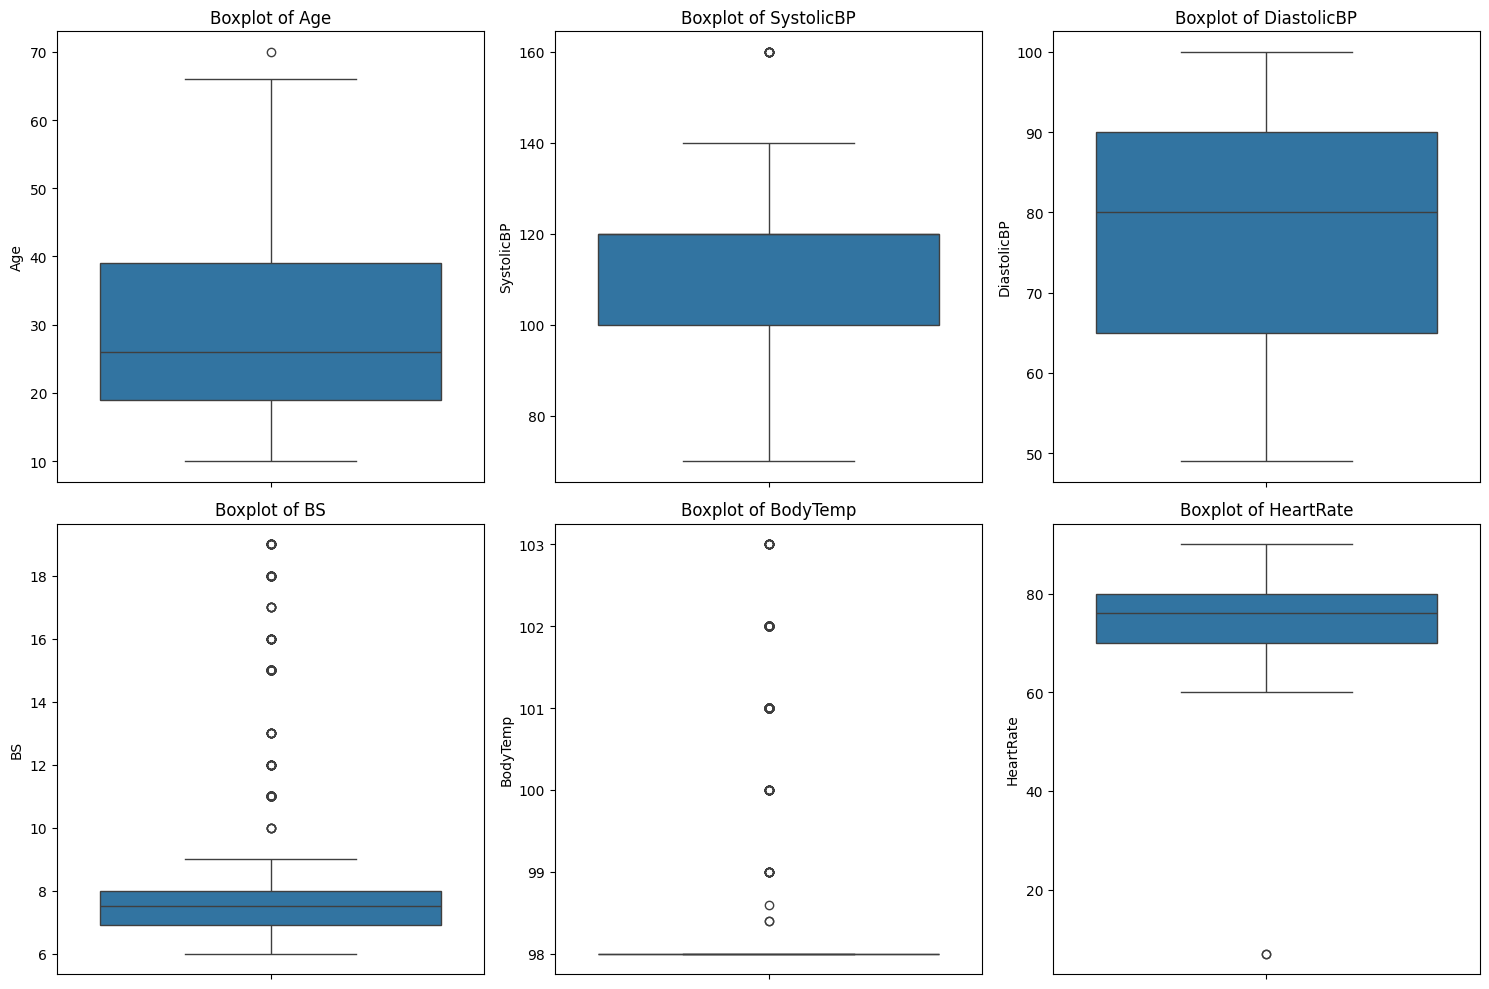

In [ ]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(df.drop(columns='RiskLevel').columns, 1):   # enumerating numerical columns only
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

### ***Outlier Observations (Insights)***

- The boxplots indicate the presence of potential outliers in most of the numerical features.
- The **Age**, **SystolicBP** and **HeartRate** columns  each contain a small number of potential outliers, with a single observation lying outside the whiskers.
- However, the **BS (Blood Sugar)** and **BodyTemp** columns  exhibit multiple potential outliers, suggesting the presence of several observations with values beyond the typical range.
- **DiastolicBP** does not display any noticeable outliers based on the boxplot.
- Given the clinical nature of the dataset, these extreme values are likely to represent genuine patient measurements rather than data entry errors. Therefore, no outliers were removed, as they may provide valuable information for predicting maternal health risk.


### ***Data Cleaning Summary***

The dataset was assessed for common data quality issues before model development.

- No missing values were found in the dataset.
- All variables were already stored in their appropriate data types.
- Although 562 duplicate rows were identified, they were retained because the dataset does not contain a unique patient identifier, making it possible for identical records to represent different individuals.
- Potential outliers were observed in several numerical features. However, these values were considered clinically plausible and were therefore retained to preserve important information for predicting maternal health risk.

Overall, the dataset was found to be clean and required no major cleaning operations. It is now ready for exploratory data analysis.

## ***Exploratory Data Analysis***

## ***1. What does the distribution of maternal health risk look like?***

- Which risk level occurs most frequently?
- Is the dataset balanced?



In [ ]:
# which risk level occurs most frequently

risk_counts = ( df['RiskLevel'] .value_counts().rename_axis('Risk Level').reset_index(name='Count'))

risk_counts

,Risk Level,Count
0,low risk,406
1,mid risk,336
2,high risk,272


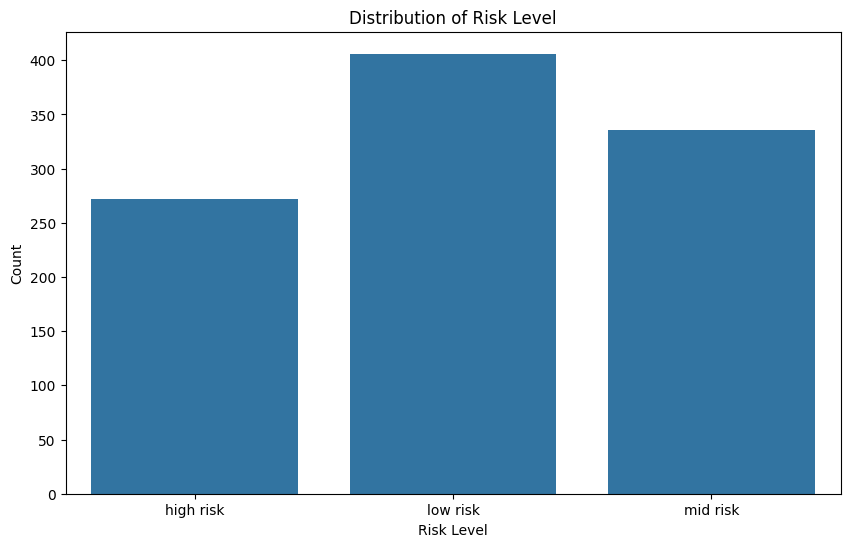

In [ ]:
#Graphical representation
plt.figure(figsize=(10, 6))

sns.countplot(data=df, x='RiskLevel')
plt.xlabel('Risk Level')
plt.ylabel('Count')
plt.title('Distribution of Risk Level')
plt.show()

### ***Insights***

- **Low Risk** pregnancies make up the largest proportion of the dataset, with **406 observations**.
- **Mid Risk** cases follow with **336 observations**, while **High Risk** cases account for **272 observations**.
- The distribution shows that the dataset is **reasonably balanced**, although the **Low Risk** class is slightly more represented than the other two categories.
- Since no single class overwhelmingly dominates the dataset, the class distribution is suitable for training a multiclass classification model. However, evaluation metrics such as **precision**, **recall**, and **F1-score** will still be considered alongside accuracy to ensure the model performs well across all risk levels.

## ***2. How are the numerical features distributed?***

- Are they normally distributed?
- Are they skewed?
- Are there unusual peaks?

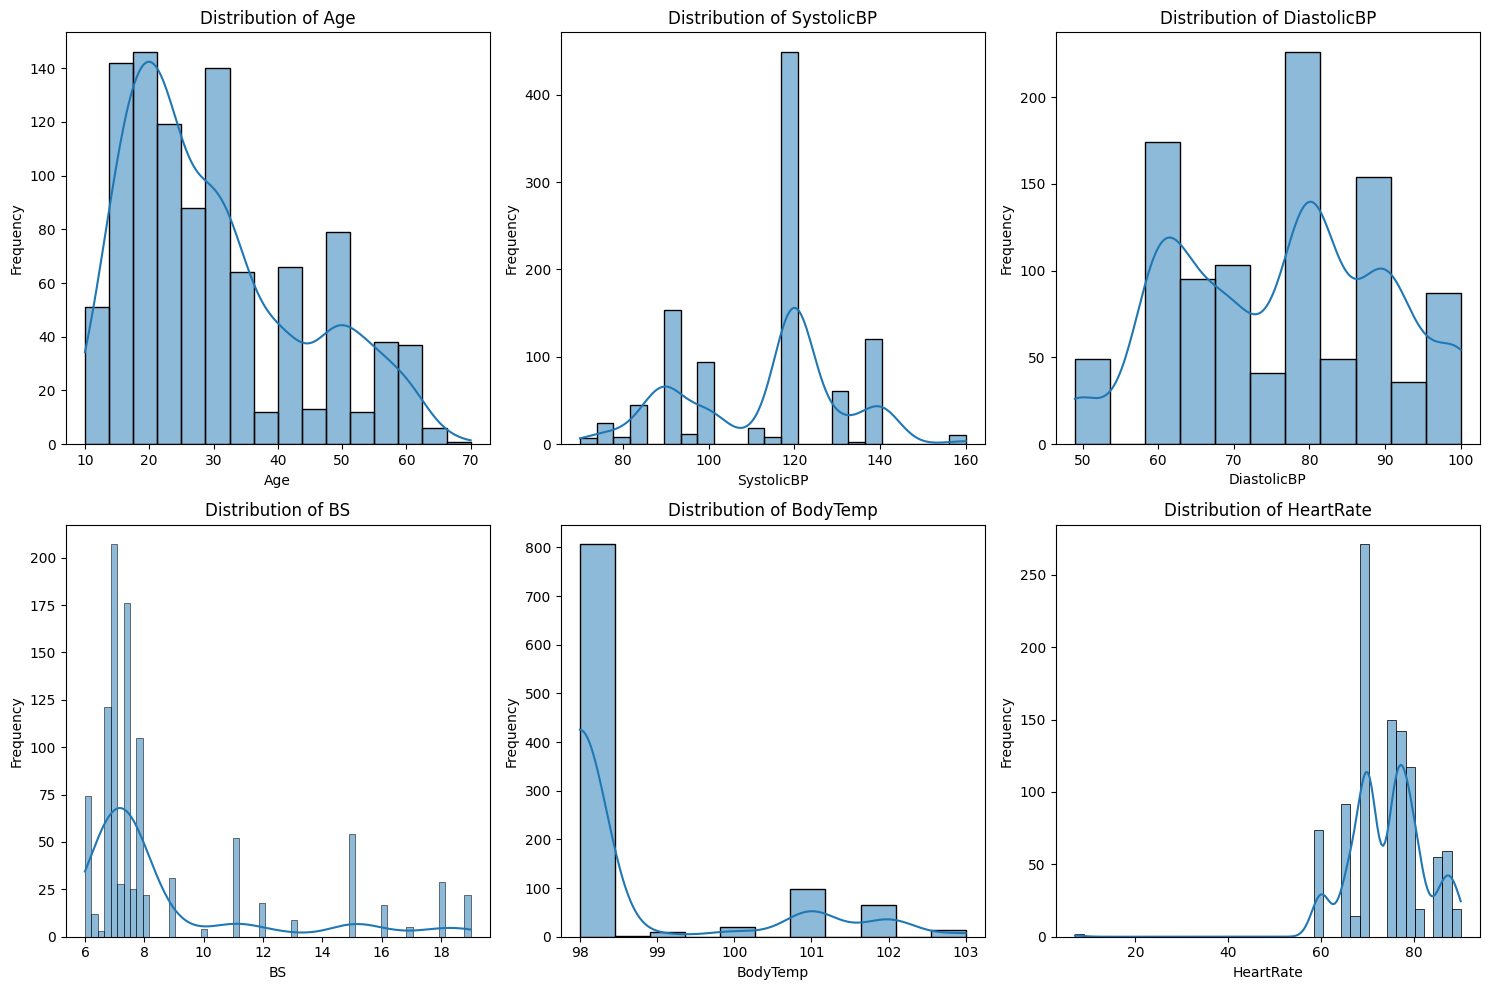

In [ ]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(df.drop(columns='RiskLevel').columns, 1):
    plt.subplot(2, 3, i)
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

### ***Insights***

- The numerical features exhibit varying distribution patterns, with most features deviating from a normal (bell-shaped) distribution.
- **Age** displays a moderately right-skewed distribution, indicating that the dataset contains more younger pregnant women than older ones.
- **SystolicBP** and **DiastolicBP** show concentrations around common clinical blood pressure values, with a few less frequent extreme measurements.
- **Blood Sugar (BS)** is highly right-skewed, with most observations clustered between **6 and 8 mmol/L** and a small number of considerably higher values. These higher values may represent women with elevated blood sugar levels.
- **Body Temperature** is heavily concentrated around **98°F**, suggesting that the majority of pregnant women in the dataset have normal body temperature, while only a few observations fall above this range.
- **Heart Rate** is primarily concentrated between **70 and 80 beats per minute**, with relatively few observations outside this interval.
- Overall, the distributions suggest that the dataset captures realistic clinical measurements, although several features exhibit skewness and clustering around common physiological values.

### **3. How do the numerical variables relate to one another?**
- Which clinical measurements are strongly correlated?

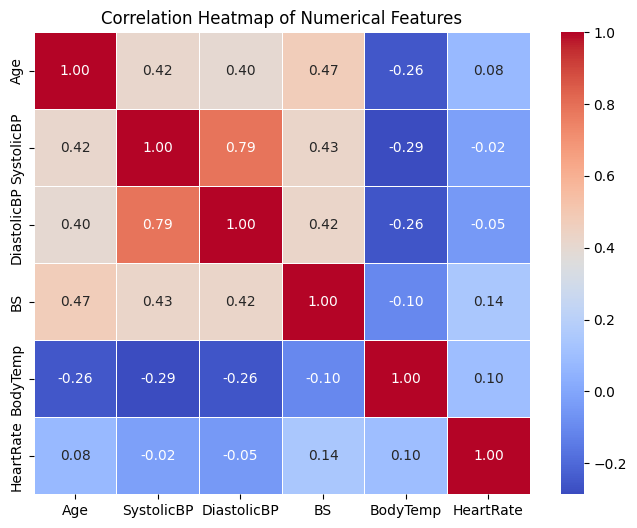

In [ ]:
# Computing the correlation matrix
corr_matrix = df.drop(columns='RiskLevel').corr()

# Plotting the correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Features')
plt.show()

### ***Insights***

- **SystolicBP** and **DiastolicBP** exhibit a **strong positive correlation (r = 0.79)**, indicating that higher systolic blood pressure is generally associated with higher diastolic blood pressure. This relationship is expected, as both measurements assess blood pressure.
- **Age** shows moderate positive correlations with **Blood Sugar (r = 0.47)**, **SystolicBP (r = 0.42)**, and **DiastolicBP (r = 0.40)**. This suggests that increases in age are associated with slight increases in blood sugar levels and blood pressure.
- **Blood Sugar (BS)** also demonstrates moderate positive correlations with both **SystolicBP (r = 0.43)** and **DiastolicBP (r = 0.42)**, indicating that elevated blood sugar levels may be accompanied by higher blood pressure measurements.
- **HeartRate** exhibits only weak positive correlations with the other numerical features, suggesting that it provides information that is relatively independent of the remaining clinical measurements.
- Overall, the correlation analysis indicates that while some clinical variables are moderately related, most feature pairs do not exhibit excessively high correlations. This suggests that the dataset is unlikely to suffer from significant multicollinearity, making the features suitable for machine learning model development.

### ***4. How do the clinical measurements vary across maternal health risk levels?***

To better understand the factors associated with maternal health risk, we examine how each clinical measurement differs across the three risk categories. Comparing the distributions of these features helps identify which variables are most closely associated with low-, mid-, and high-risk pregnancies.

The following questions are explored:

- Does maternal age appear to influence pregnancy risk?
- Does blood pressure increase with maternal health risk?
- Are higher blood sugar levels associated with increased risk?
- Is elevated body temperature more common among high-risk pregnancies?
- Do heart rate patterns differ across the risk levels?

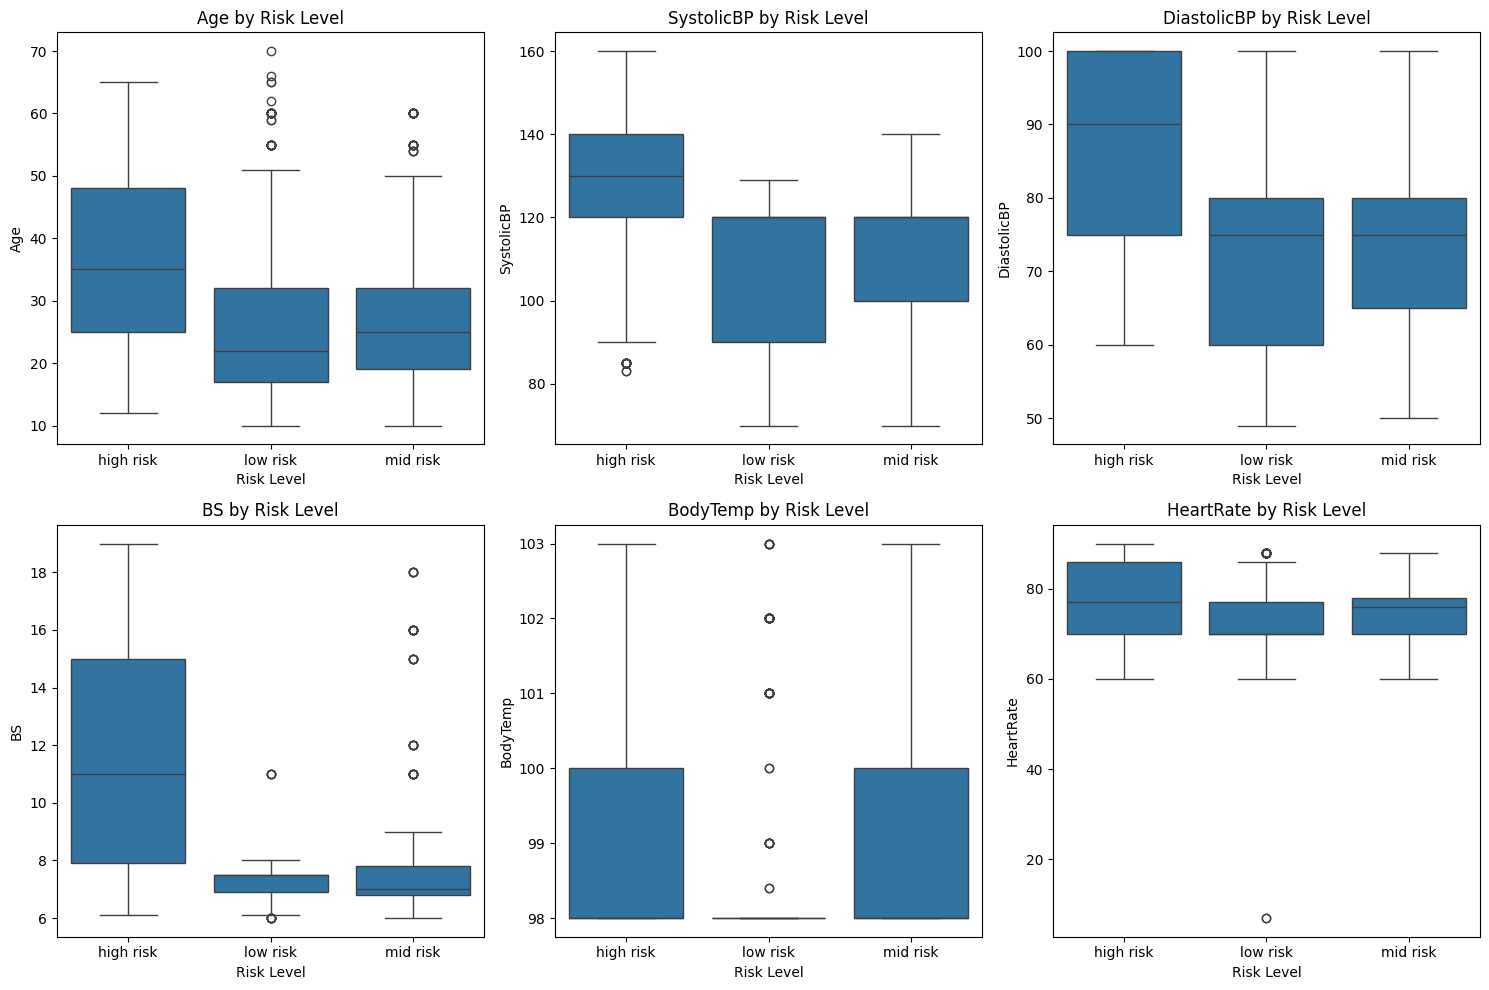

In [ ]:
features = ['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate']

plt.figure(figsize=(15, 10))

for i, feature in enumerate(features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(data=df, x='RiskLevel', y=feature)
    plt.title(f'{feature} by Risk Level')
    plt.xlabel('Risk Level')
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

### ***Insights***

- **Blood Sugar (BS)** demonstrates the clearest distinction across the maternal health risk categories. High-risk pregnancies exhibit noticeably higher blood sugar levels than both low- and mid-risk pregnancies, suggesting that blood sugar is one of the strongest indicators of maternal health risk.
- **SystolicBP** and **DiastolicBP** also show clear differences across the risk groups, with high-risk pregnancies generally recording higher blood pressure measurements.
- **Age** exhibits moderate variation across the three risk categories. While high-risk pregnancies tend to involve slightly older mothers, there is considerable overlap between the groups, indicating that age alone is unlikely to be a strong predictor.
- **Body Temperature** shows only slight differences across the risk levels, with most observations clustered around normal body temperature.
- **Heart Rate** displays substantial overlap across all three maternal health risk categories, suggesting that it may contribute less to distinguishing between the different risk levels when considered independently.

Overall, the boxplots indicate that **Blood Sugar**, **Systolic Blood Pressure**, and **Diastolic Blood Pressure** provide the clearest separation between maternal health risk categories and are likely to be among the most influential predictors in the machine learning models.

### ***Feature Engineering and Data Preprocessing***

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Create a LabelEncoder object
label_encoder = LabelEncoder()

# Encode the target variable
df['RiskLevel'] = label_encoder.fit_transform(df['RiskLevel'])

# Preview the encoded values
df.head()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,0
1,35,140,90,13.0,98.0,70,0
2,29,90,70,8.0,100.0,80,0
3,30,140,85,7.0,98.0,70,0
4,35,120,60,6.1,98.0,76,1


In [ ]:
mapping = dict(zip(label_encoder.classes_,
                   label_encoder.transform(label_encoder.classes_)))

mapping

{'high risk': np.int64(0), 'low risk': np.int64(1), 'mid risk': np.int64(2)}

### **Insights**

The target variable has been successfully encoded into numerical labels, making it suitable for machine learning algorithms. The mapping between the original risk categories and their encoded values will be retained and later used to convert model predictions back into their corresponding maternal health risk categories.

In [ ]:
# Define Feature matrix and target variable

# Feature matrix
X = df.drop('RiskLevel', axis=1)

# Target variable
y = df['RiskLevel']

print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Matrix Shape: (1014, 6)
Target Shape: (1014,)


In [ ]:
#train test split

from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (811, 6)
Testing set: (203, 6)


The dataset was split into **80% training data** and **20% testing data**. Stratified sampling was used to preserve the original distribution of the maternal health risk classes in both subsets, ensuring a fair evaluation of model performance.

In [ ]:
# Feature Scaling

from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Scale the training and testing data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

The numerical features were successfully standardized using **StandardScaler**. Scaling ensures that all variables contribute equally during model training and is especially important for algorithms such as Support Vector Classifier (SVC). The unscaled dataset will also be retained for evaluating tree-based models, which are generally unaffected by feature scaling.

## ***Model Development***

The models selected for this project are:

- Decision Tree Classifier
- Gradient Boosting Classifier
- Extreme Gradient Boosting (XGBoost)
- Support Vector Classifier (SVC)

These models were chosen because they represent different machine learning approaches, allowing for a comprehensive comparison of predictive performance.
Import Models

In [ ]:
# import models

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

In [ ]:
# Initialize the models
decision_tree = DecisionTreeClassifier(random_state=42)

gradient_boost = GradientBoostingClassifier(random_state=42)

xgb = XGBClassifier(
    random_state=42,
    eval_metric='mlogloss'
)

svc = SVC(random_state=42)

In [ ]:
# Train Decision Tree
decision_tree.fit(X_train, y_train)

# Train Gradient Boosting
gradient_boost.fit(X_train, y_train)

# Train XGBoost
xgb.fit(X_train, y_train)

# Train Support Vector Classifier
svc.fit(X_train_scaled, y_train)

SVC(random_state=42)

In [ ]:
# Decision Tree predictions
dt_pred = decision_tree.predict(X_test)

# Gradient Boosting predictions
gb_pred = gradient_boost.predict(X_test)

# XGBoost predictions
xgb_pred = xgb.predict(X_test)

# SVC predictions
svc_pred = svc.predict(X_test_scaled)

### ***Model Evaluation***

The performance of each machine learning model is evaluated using multiple classification metrics to provide a comprehensive assessment of predictive performance.

The evaluation metrics considered include:

- **Accuracy:** Measures the proportion of correctly classified observations.
- **Precision:** Measures the proportion of positive predictions that are correct.
- **Recall:** Measures the proportion of actual positive cases that are correctly identified.
- **F1-Score:** Provides a balance between precision and recall.
- **Confusion Matrix:** Visualizes the classification performance by comparing actual and predicted classes.

Using multiple evaluation metrics provides a more reliable assessment than relying on accuracy alone.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [ ]:
# Evaluate models

#Decision tree model evaluation
dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred, average='weighted')
dt_recall = recall_score(y_test, dt_pred, average='weighted')
dt_f1 = f1_score(y_test, dt_pred, average='weighted')

# Gradient boost model evaluation

gb_accuracy = accuracy_score(y_test, gb_pred)
gb_precision = precision_score(y_test, gb_pred, average='weighted')
gb_recall = recall_score(y_test, gb_pred, average='weighted')
gb_f1 = f1_score(y_test, gb_pred, average='weighted')


# XG boost model evaluation
xgb_accuracy = accuracy_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred, average='weighted')
xgb_recall = recall_score(y_test, xgb_pred, average='weighted')
xgb_f1 = f1_score(y_test, xgb_pred, average='weighted')

# SVC model evaluation

svc_accuracy = accuracy_score(y_test, svc_pred)
svc_precision = precision_score(y_test, svc_pred, average='weighted')
svc_recall = recall_score(y_test, svc_pred, average='weighted')
svc_f1 = f1_score(y_test, svc_pred, average='weighted')




In [ ]:
# COMPARE MODELS

comparison = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Gradient Boosting',
        'XGBoost',
        'Support Vector Classifier'
    ],
    'Accuracy': [
        dt_accuracy,
        gb_accuracy,
        xgb_accuracy,
        svc_accuracy
    ],
    'Precision': [
        dt_precision,
        gb_precision,
        xgb_precision,
        svc_precision
    ],
    'Recall': [
        dt_recall,
        gb_recall,
        xgb_recall,
        svc_recall
    ],
    'F1 Score': [
        dt_f1,
        gb_f1,
        xgb_f1,
        svc_f1
    ]
})

comparison = comparison.sort_values(by='Accuracy', ascending=False)

comparison.style.highlight_max(
    subset=['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    color='green'
)  #highlights the best performing model

,Model,Accuracy,Precision,Recall,F1 Score
2,XGBoost,0.857143,0.865814,0.857143,0.858420
0,Decision Tree,0.837438,0.855618,0.837438,0.840048
1,Gradient Boosting,0.768473,0.777962,0.768473,0.771760
3,Support Vector Classifier,0.724138,0.743129,0.724138,0.708454


### ***Insights***

The performance of the four machine learning models was compared using **Accuracy**, **Precision**, **Recall**, and **F1-Score**.

Among the evaluated models, **XGBoost** achieved the best overall performance with an **accuracy of 85.71%**, alongside the highest precision, recall, and F1-score. This indicates that XGBoost was the most effective at distinguishing between the three maternal health risk categories while maintaining a balanced classification performance across all metrics.

The **Decision Tree Classifier** ranked second with an accuracy of **83.74%**. Although its performance was competitive, it was slightly outperformed by XGBoost, likely because boosting methods combine the predictions of multiple trees to produce a more robust model.

The **Gradient Boosting Classifier** achieved a moderate accuracy of **76.85%**, while the **Support Vector Classifier (SVC)** recorded the lowest accuracy of **72.41%**. Although SVC benefited from feature scaling, it was less effective than the tree-based ensemble methods for this multiclass classification problem.

- Based on the evaluation results, **XGBoost** was selected as the best-performing model and will be further optimized using **GridSearchCV** to determine whether its predictive performance can be improved through hyperparameter tuning.

### ***Hyperparameter Tuning with GridSearch CV***

The initial evaluation identified **XGBoost** as the best-performing model. To further optimize its predictive performance, **GridSearchCV** is applied to search for the optimal combination of hyperparameters.

**GridSearchCV** systematically evaluates multiple parameter combinations using cross-validation and selects the configuration that produces the best average performance. Although hyperparameter tuning does not always lead to a significant improvement, it is considered a best practice for developing robust machine learning models.

In [ ]:
#import gridsearch CV
from sklearn.model_selection import GridSearchCV

### ***Defining the Hyperparameter Grid***

- **n_estimators:** Number of boosting trees.
- **max_depth:** Maximum depth of each tree.
- **learning_rate:** Controls how quickly the model learns.
- **subsample:** Fraction of the training data used to build each tree.

In [ ]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.8, 1.0]
}

In [ ]:
# Apply the grid search

grid_search = GridSearchCV(
    estimator=XGBClassifier(
        random_state=42,
        eval_metric='mlogloss'
    ),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=True,
                                     eval_metric='mlogloss', feature_types=None,
                                     feature_weights=None, gamma=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraint...
                                     max_cat_threshold=None,
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'learning_rate': [0.01, 0.1], 'max_depth': [3, 5],
                         'n_estimators': [100, 200], 'subsample': [0.8, 1.0]},
             scoring='accuracy')

In [ ]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation Accuracy:")
print(grid_search.best_score_)

Best Parameters:
{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 0.8}

Best Cross Validation Accuracy:
0.8138226160721048


In [ ]:
# retrieve best model

best_model = grid_search.best_estimator_

In [ ]:
# use tuned model for prediction

best_pred = best_model.predict(X_test)

In [ ]:
# Evaluate tuned model

best_accuracy = accuracy_score(y_test, best_pred)
best_precision = precision_score(y_test, best_pred, average='weighted')
best_recall = recall_score(y_test, best_pred, average='weighted')
best_f1 = f1_score(y_test, best_pred, average='weighted')

print(f"Accuracy : {best_accuracy:.4f}")
print(f"Precision: {best_precision:.4f}")
print(f"Recall   : {best_recall:.4f}")
print(f"F1 Score : {best_f1:.4f}")

Accuracy : 0.8670
Precision: 0.8718
Recall   : 0.8670
F1 Score : 0.8678


In [ ]:
# compare model before and after tuning

comparison_tuned = pd.DataFrame({
    'Model': ['XGBoost (Before Tuning)', 'XGBoost (After Tuning)'],
    'Accuracy': [xgb_accuracy, best_accuracy],
    'Precision': [xgb_precision, best_precision],
    'Recall': [xgb_recall, best_recall],
    'F1 Score': [xgb_f1, best_f1]
})

comparison_tuned

,Model,Accuracy,Precision,Recall,F1 Score
0,XGBoost (Before Tuning),0.857143,0.865814,0.857143,0.858420
1,XGBoost (After Tuning),0.866995,0.871776,0.866995,0.867786


### **Insights**

Following the initial model comparison, **XGBoost** was selected for hyperparameter tuning using **GridSearchCV**. The objective was to identify the optimal combination of hyperparameters that would further enhance the model's predictive performance.

The tuned XGBoost model demonstrated a modest improvement across all evaluation metrics. Model accuracy increased from **85.71%** to **86.70%**, while precision, recall, and F1-score also improved slightly. Although the performance gain was relatively small, it indicates that the optimized hyperparameter configuration enabled the model to generalize better to unseen data.

Overall, the tuned **XGBoost** model achieved the best predictive performance among all evaluated models and was selected as the final model for deployment in the maternal health risk prediction application.

### ***Feature Importance***

Understanding which features contribute most to a model's predictions is essential for interpreting its behaviour. Since **XGBoost** was selected as the best-performing model, its built-in feature importance scores are used to identify the clinical measurements that have the greatest influence on maternal health risk prediction.

This analysis provides valuable insight into the relative importance of each feature and helps explain how the model arrives at its predictions.

In [ ]:
# Create a DataFrame of feature importances
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_model.feature_importances_
})

# Sort in descending order
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

,Feature,Importance
1,SystolicBP,0.293808
3,BS,0.235615
4,BodyTemp,0.195014
0,Age,0.100732
5,HeartRate,0.088643
2,DiastolicBP,0.086188


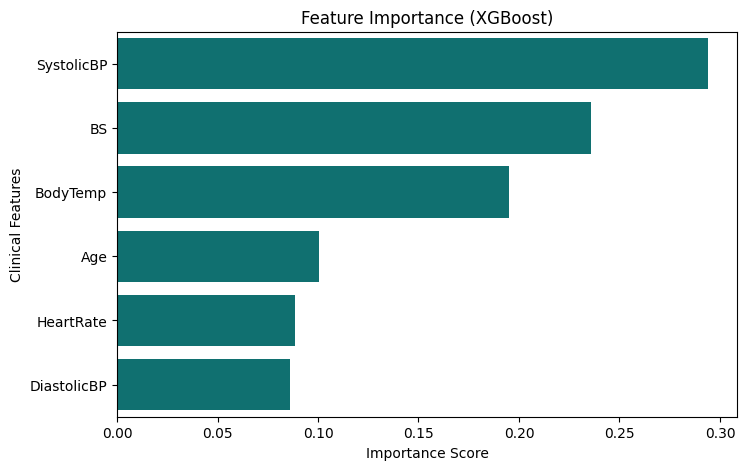

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature',
    color = 'teal'
)

plt.title("Feature Importance (XGBoost)")
plt.xlabel("Importance Score")
plt.ylabel("Clinical Features")

plt.show()

### ***Insights***

The feature importance analysis provides insight into the clinical measurements that contributed most to the predictions made by the tuned XGBoost model.

- Among all the features, **Systolic Blood Pressure** emerged as the most influential predictor, accounting for approximately **29.4%** of the model's decision-making process. This highlights the significant role of elevated systolic blood pressure in identifying maternal health risk.

- **Blood Sugar (BS)** ranked as the second most important feature, reinforcing the observations from the exploratory data analysis that higher blood sugar levels are strongly associated with increased maternal health risk.

- Interestingly, **Body Temperature** was identified as the third most influential feature despite showing only modest differences across the risk categories during the exploratory analysis. This suggests that while Body Temperature may appear less informative when examined independently, it provides valuable predictive information when considered alongside other clinical measurements.

- **Age**, **Heart Rate**, and **Diastolic Blood Pressure** contributed comparatively less to the model's predictions. However, they still provide complementary information that helps improve the model's overall predictive performance.

Overall, the feature importance analysis demonstrates that the tuned XGBoost model relies primarily on **Systolic Blood Pressure**, **Blood Sugar**, and **Body Temperature** when predicting maternal health risk, providing valuable insight into the factors driving the model's decisions.

In [ ]:
# saving the best model

import joblib
joblib.dump(best_model, 'maternal_health_model.pkl')

# save the label encoder
joblib.dump(label_encoder, 'label_encoder.pkl')

# save the scaler
joblib.dump(scaler, 'scaler.pkl')

print("All files saved successfully!")

All files saved successfully!


In [ ]:
# verify saved files

import os

saved_files = [
    "maternal_health_model.pkl",
    "label_encoder.pkl",
    "scaler.pkl"
]

for file in saved_files:
    if os.path.exists(file):
        print(f"✅ {file} saved successfully.")
    else:
        print(f"❌ {file} not found.")

✅ maternal_health_model.pkl saved successfully.
✅ label_encoder.pkl saved successfully.
✅ scaler.pkl saved successfully.
